# Concrete Strength Prediction

Predict concrete compressive strength from eight mixture and age features.

See [README.md](README.md) for data, setup, workflow, and evaluation notes.

In [1]:
import random
import numpy as np
import torch
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset,DataLoader
import torch.optim as optim

In [3]:
concrete_df = pd.read_excel("concrete_data.xls")

In [4]:
concrete_df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [5]:
concrete_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

In [6]:
concrete_df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [7]:
concrete_df.isnull().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

In [8]:
concrete_df.columns

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='str')

In [9]:
X = concrete_df.drop("Concrete compressive strength(MPa, megapascals) ",axis=1)
y = concrete_df["Concrete compressive strength(MPa, megapascals) "]

In [10]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

# Keep the test set untouched during checkpoint selection.
X_train,X_val,y_train,y_val = train_test_split(
    X_train,y_train,test_size=0.2,random_state=42
)
print(f"Train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")


Train: 659, validation: 165, test: 206


In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_val_scaled = scaler.transform(X_val)


In [12]:
X_train_tensor = torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor = torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)
X_val_tensor = torch.tensor(X_val_scaled,dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values,dtype=torch.float32).view(-1,1)


In [13]:
train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)
val_dataset = TensorDataset(X_val_tensor,y_val_tensor)


In [14]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32)
val_loader = DataLoader(val_dataset,batch_size=32)


In [15]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model = nn.Sequential(

            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),

            nn.Linear(6,6),
            nn.ReLU(),

            nn.Linear(6,1),
        )

    def forward(self,x):
        return self.model(x)

In [16]:
model = ANN()

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [17]:
train_losses = []
val_losses = []
epochs = 100

best_val_loss = float("inf") 

for epoch in range(epochs):
    model.train()

    running_loss = 0.0
    for xb,yb in train_loader:
    
        optimizer.zero_grad()
    
        outputs = model(xb)
        loss = criterion(outputs,yb)
        loss.backward()
        optimizer.step()
    
        running_loss += loss.item() * xb.size(0)
        
    epoch_train_loss = running_loss/len(train_dataset)
    train_losses.append(epoch_train_loss)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb,yb in val_loader:
            outputs = model(xb)
            loss = criterion(outputs,yb)
            running_val_loss += loss.item() * xb.size(0)

    epoch_val_loss = running_val_loss/len(val_dataset)
    val_losses.append(epoch_val_loss)

    print(
    f"Epoch {epoch+1}/{epochs} ==> "
    f"Training Loss = {epoch_train_loss:.4f} | "
    f"Validation Loss = {epoch_val_loss:.4f}"
)       

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt") #pt or pth file

Epoch 1/100 ==> Training Loss = 1602.9372 | Validation Loss = 1479.5125
Epoch 2/100 ==> Training Loss = 1595.5914 | Validation Loss = 1472.4151
Epoch 3/100 ==> Training Loss = 1588.5319 | Validation Loss = 1465.2612
Epoch 4/100 ==> Training Loss = 1581.3805 | Validation Loss = 1457.6140
Epoch 5/100 ==> Training Loss = 1573.4859 | Validation Loss = 1448.8471
Epoch 6/100 ==> Training Loss = 1564.2668 | Validation Loss = 1438.2450
Epoch 7/100 ==> Training Loss = 1552.8773 | Validation Loss = 1425.3276
Epoch 8/100 ==> Training Loss = 1538.9598 | Validation Loss = 1408.6746
Epoch 9/100 ==> Training Loss = 1521.2250 | Validation Loss = 1387.8569
Epoch 10/100 ==> Training Loss = 1499.3144 | Validation Loss = 1361.6283
Epoch 11/100 ==> Training Loss = 1471.7741 | Validation Loss = 1330.7574
Epoch 12/100 ==> Training Loss = 1440.0233 | Validation Loss = 1292.8673
Epoch 13/100 ==> Training Loss = 1401.7860 | Validation Loss = 1250.2121
Epoch 14/100 ==> Training Loss = 1358.1151 | Validation Loss

Epoch 15/100 ==> Training Loss = 1307.8606 | Validation Loss = 1145.6231
Epoch 16/100 ==> Training Loss = 1252.7899 | Validation Loss = 1083.6692
Epoch 17/100 ==> Training Loss = 1191.1387 | Validation Loss = 1016.3274
Epoch 18/100 ==> Training Loss = 1123.8199 | Validation Loss = 946.5508
Epoch 19/100 ==> Training Loss = 1053.4219 | Validation Loss = 872.2046
Epoch 20/100 ==> Training Loss = 978.3173 | Validation Loss = 798.3681
Epoch 21/100 ==> Training Loss = 901.5549 | Validation Loss = 721.5861
Epoch 22/100 ==> Training Loss = 821.8605 | Validation Loss = 645.6495
Epoch 23/100 ==> Training Loss = 744.0666 | Validation Loss = 573.0654
Epoch 24/100 ==> Training Loss = 668.0954 | Validation Loss = 509.1165
Epoch 25/100 ==> Training Loss = 599.4471 | Validation Loss = 450.5042
Epoch 26/100 ==> Training Loss = 535.6419 | Validation Loss = 400.4468
Epoch 27/100 ==> Training Loss = 478.9065 | Validation Loss = 358.6230
Epoch 28/100 ==> Training Loss = 430.6407 | Validation Loss = 324.440

Epoch 29/100 ==> Training Loss = 388.7937 | Validation Loss = 298.6337
Epoch 30/100 ==> Training Loss = 354.7276 | Validation Loss = 278.2156
Epoch 31/100 ==> Training Loss = 326.6255 | Validation Loss = 264.0119
Epoch 32/100 ==> Training Loss = 304.1328 | Validation Loss = 254.6787
Epoch 33/100 ==> Training Loss = 287.1847 | Validation Loss = 248.1459
Epoch 34/100 ==> Training Loss = 273.4704 | Validation Loss = 243.6000
Epoch 35/100 ==> Training Loss = 262.7058 | Validation Loss = 239.2810
Epoch 36/100 ==> Training Loss = 253.5052 | Validation Loss = 237.1183
Epoch 37/100 ==> Training Loss = 246.0038 | Validation Loss = 234.0969
Epoch 38/100 ==> Training Loss = 239.1076 | Validation Loss = 231.6503
Epoch 39/100 ==> Training Loss = 232.8979 | Validation Loss = 227.5780
Epoch 40/100 ==> Training Loss = 226.9986 | Validation Loss = 224.0672
Epoch 41/100 ==> Training Loss = 221.4717 | Validation Loss = 221.0612
Epoch 42/100 ==> Training Loss = 216.2731 | Validation Loss = 217.5067


Epoch 43/100 ==> Training Loss = 211.3664 | Validation Loss = 214.3315
Epoch 44/100 ==> Training Loss = 206.8745 | Validation Loss = 211.2127
Epoch 45/100 ==> Training Loss = 202.6621 | Validation Loss = 207.6306
Epoch 46/100 ==> Training Loss = 198.5100 | Validation Loss = 204.8470
Epoch 47/100 ==> Training Loss = 194.8117 | Validation Loss = 202.0705
Epoch 48/100 ==> Training Loss = 191.2715 | Validation Loss = 197.9239
Epoch 49/100 ==> Training Loss = 187.6243 | Validation Loss = 195.2389
Epoch 50/100 ==> Training Loss = 184.4640 | Validation Loss = 192.1688
Epoch 51/100 ==> Training Loss = 181.5285 | Validation Loss = 190.4380
Epoch 52/100 ==> Training Loss = 178.3676 | Validation Loss = 187.6039
Epoch 53/100 ==> Training Loss = 175.9233 | Validation Loss = 184.6499
Epoch 54/100 ==> Training Loss = 173.4274 | Validation Loss = 183.3574


Epoch 55/100 ==> Training Loss = 170.9889 | Validation Loss = 180.8442
Epoch 56/100 ==> Training Loss = 168.6906 | Validation Loss = 178.2161
Epoch 57/100 ==> Training Loss = 166.6862 | Validation Loss = 176.4655
Epoch 58/100 ==> Training Loss = 164.5210 | Validation Loss = 173.4675
Epoch 59/100 ==> Training Loss = 162.6044 | Validation Loss = 171.8073
Epoch 60/100 ==> Training Loss = 160.6366 | Validation Loss = 169.8521
Epoch 61/100 ==> Training Loss = 158.9385 | Validation Loss = 168.5019
Epoch 62/100 ==> Training Loss = 157.2608 | Validation Loss = 166.7094
Epoch 63/100 ==> Training Loss = 155.8300 | Validation Loss = 165.2479
Epoch 64/100 ==> Training Loss = 154.2373 | Validation Loss = 163.4991
Epoch 65/100 ==> Training Loss = 152.9281 | Validation Loss = 161.8951
Epoch 66/100 ==> Training Loss = 151.4749 | Validation Loss = 161.3436
Epoch 67/100 ==> Training Loss = 150.1055 | Validation Loss = 160.0076


Epoch 68/100 ==> Training Loss = 148.9188 | Validation Loss = 159.0498
Epoch 69/100 ==> Training Loss = 147.8246 | Validation Loss = 157.5608
Epoch 70/100 ==> Training Loss = 146.6853 | Validation Loss = 156.4085
Epoch 71/100 ==> Training Loss = 145.5986 | Validation Loss = 155.2574
Epoch 72/100 ==> Training Loss = 144.6271 | Validation Loss = 153.8807
Epoch 73/100 ==> Training Loss = 143.6520 | Validation Loss = 153.2794
Epoch 74/100 ==> Training Loss = 142.7708 | Validation Loss = 151.9873
Epoch 75/100 ==> Training Loss = 141.9524 | Validation Loss = 150.4815
Epoch 76/100 ==> Training Loss = 141.2142 | Validation Loss = 149.7219
Epoch 77/100 ==> Training Loss = 140.2851 | Validation Loss = 148.8360
Epoch 78/100 ==> Training Loss = 139.6048 | Validation Loss = 148.1050
Epoch 79/100 ==> Training Loss = 138.9728 | Validation Loss = 146.3514
Epoch 80/100 ==> Training Loss = 138.1909 | Validation Loss = 145.4216
Epoch 81/100 ==> Training Loss = 137.3858 | Validation Loss = 145.6042


Epoch 82/100 ==> Training Loss = 136.8487 | Validation Loss = 144.4336
Epoch 83/100 ==> Training Loss = 136.0907 | Validation Loss = 143.9968
Epoch 84/100 ==> Training Loss = 135.3409 | Validation Loss = 143.1508
Epoch 85/100 ==> Training Loss = 134.7282 | Validation Loss = 141.6177
Epoch 86/100 ==> Training Loss = 134.0938 | Validation Loss = 141.5740
Epoch 87/100 ==> Training Loss = 133.1921 | Validation Loss = 140.5810
Epoch 88/100 ==> Training Loss = 132.5402 | Validation Loss = 139.7872
Epoch 89/100 ==> Training Loss = 131.8929 | Validation Loss = 139.2996
Epoch 90/100 ==> Training Loss = 131.2751 | Validation Loss = 138.1143
Epoch 91/100 ==> Training Loss = 130.6114 | Validation Loss = 137.9627
Epoch 92/100 ==> Training Loss = 129.9360 | Validation Loss = 137.0995
Epoch 93/100 ==> Training Loss = 129.3008 | Validation Loss = 136.0298
Epoch 94/100 ==> Training Loss = 128.7162 | Validation Loss = 135.3167


Epoch 95/100 ==> Training Loss = 128.1007 | Validation Loss = 134.7355
Epoch 96/100 ==> Training Loss = 127.5651 | Validation Loss = 134.0115
Epoch 97/100 ==> Training Loss = 127.0010 | Validation Loss = 134.2772
Epoch 98/100 ==> Training Loss = 126.3340 | Validation Loss = 133.2267
Epoch 99/100 ==> Training Loss = 125.8613 | Validation Loss = 132.4807
Epoch 100/100 ==> Training Loss = 125.2938 | Validation Loss = 130.9313


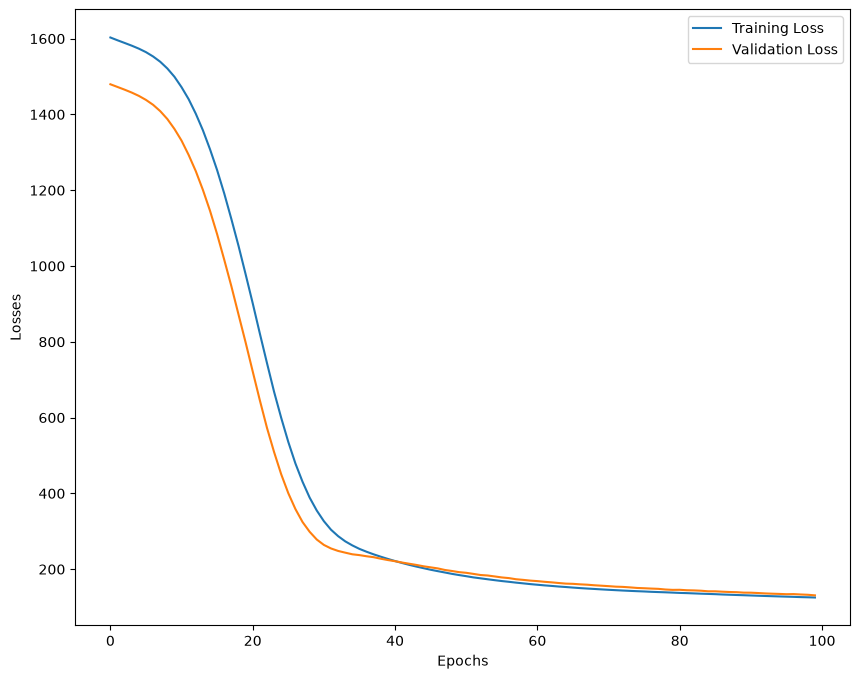

In [18]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss" : train_losses,
    "Validation Loss" : val_losses
})

plt.figure(figsize=(10,8))
plt.plot(loss_df["Training Loss"],label="Training Loss")
plt.plot(loss_df["Validation Loss"],label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [19]:
# Restore the checkpoint selected only on validation data.
model.load_state_dict(torch.load("best_model.pt",weights_only=True))


<All keys matched successfully>

In [20]:
#Evaluate our Model

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds,y_train_tensor)
    test_mse_loss = criterion(test_preds,y_test_tensor)
    
print("Training MSE : ",train_mse_loss.item())
print("Testing MSE : ",test_mse_loss.item())

Training MSE :  124.69584655761719
Testing MSE :  119.38973236083984


In [21]:
from sklearn.metrics import r2_score

print("R2 Score : ",r2_score(y_test,test_preds.numpy()))

R2 Score :  0.5366763663367224


In [22]:
predicted_df = pd.DataFrame(test_preds.numpy(),columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values,columns=["Actual Values"])

pd.concat([predicted_df,actual_df],axis=1)

,Predicted Values,Actual Values
0,55.881260,52.908320
1,52.272175,55.895819
2,68.197968,74.497882
3,51.673763,35.301171
4,34.842262,10.535193
...,...,...
201,54.915096,56.144031
202,14.677629,18.746163
203,50.567223,37.997022
204,52.460529,74.364911


## Final test metrics and prediction diagnostics
The held-out test set is evaluated after selecting the checkpoint on a separate validation set.

MAE      8.759095
RMSE    10.926561
R2       0.536676
Name: Held-out test metrics, dtype: float64


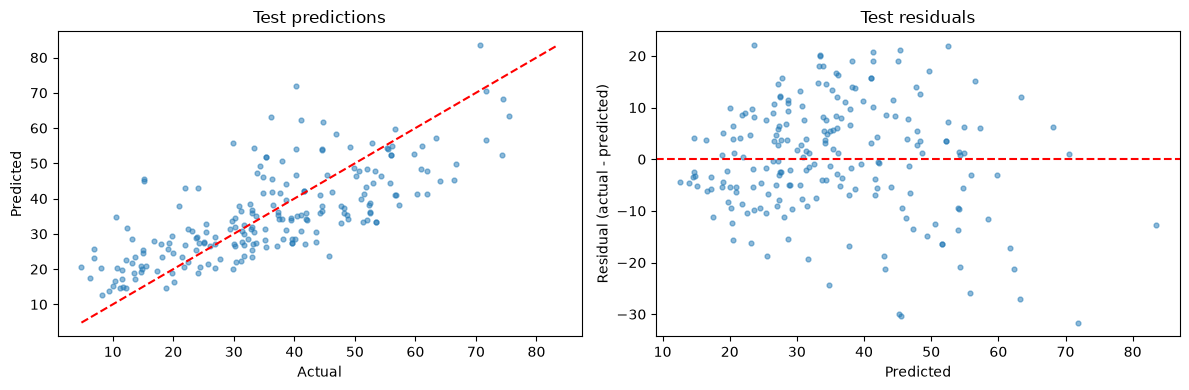

,Actual,Predicted
0,52.908320,55.881260
1,55.895819,52.272175
2,74.497882,68.197968
3,35.301171,51.673763
4,10.535193,34.842262
5,44.284354,35.850475
6,23.690395,25.369968
7,45.367521,46.741070
8,37.404073,34.184246
9,48.846617,34.292095


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

actual = y_test.to_numpy()
predictions = test_preds.numpy().ravel()
results = {
    "MAE": mean_absolute_error(actual, predictions),
    "RMSE": float(np.sqrt(mean_squared_error(actual, predictions))),
    "R2": r2_score(actual, predictions),
}
print(pd.Series(results, name="Held-out test metrics"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(actual, predictions, alpha=0.5, s=12)
limits = [min(actual.min(), predictions.min()), max(actual.max(), predictions.max())]
axes[0].plot(limits, limits, "r--")
axes[0].set(xlabel="Actual", ylabel="Predicted", title="Test predictions")
axes[1].scatter(predictions, actual - predictions, alpha=0.5, s=12)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set(xlabel="Predicted", ylabel="Residual (actual - predicted)", title="Test residuals")
plt.tight_layout()
plt.show()
pd.DataFrame({"Actual": actual, "Predicted": predictions}).head(10)
